# One positional argument, and two benchmark rows that meant nothing

`flax.linen.RMSNorm`'s first positional argument is `epsilon`. In PyTorch the
first argument of `nn.RMSNorm` is `normalized_shape`. Mamba3 was written with
the PyTorch reading, so `nn.RMSNorm(d_state)` set **epsilon to the feature
count** -- 128, 1024 or 2048 instead of 1e-6.

Commits `ffe45d66` / `13f04e52` (2026-04-22) corrected it. Checkpoints trained
before that date learned their weights under the large epsilon, and
`src/lobpipeline/model_store_pins.json` records which ones. The model-zoo
benchmark harness did not read that record, so two checkpoints were scored
under a normalizer they had never seen.

This notebook profiles what that does, and measures what it cost. Numbers come
from `docs/evidence/zoo_benchmark.json`.

In [1]:
import io, json, pathlib, statistics as st
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

EV = pathlib.Path("docs/evidence/zoo_benchmark.json")
if not EV.exists():
    EV = pathlib.Path("..") / ".." / "docs/evidence/zoo_benchmark.json"
E = json.loads(EV.read_text())
REG, PINS = E["registry"], E["pins_legacy_norm"]
FIXED, LEGACY, HIST = E["fixed_eps"], E["legacy_eps"], E["historical_78m"]

INK, WARN, GREY, GOOD = "#1f4e79", "#c05a00", "#93a5b5", "#3d7a5a"
EPS_FIXED = 1e-6
plt.rcParams.update({"figure.dpi": 300, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
plt.ioff()

def show(fig):
    buf = io.BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight")
    plt.close(fig); buf.seek(0)
    try:
        from PIL import Image as _PIL
        im = _PIL.open(buf).convert("RGB").quantize(colors=256)
        out = io.BytesIO(); im.save(out, format="PNG", optimize=True)
        display(Image(data=out.getvalue()))
    except ImportError:
        display(Image(data=buf.getvalue()))

def ws(d, m):
    return [v["ws21"] for _, v in sorted(d.get(m, {}).items())]

# The two checkpoints the pin flags and that the runtime can load.
FLAGGED = sorted(LEGACY)
print("checkpoints re-scored under the epsilon they were trained with:")
for m in FLAGGED:
    print(f"  {m:24} pin={PINS.get(m)!r:10} d_model={REG[m]['d_model']}")

checkpoints re-scored under the epsilon they were trained with:
  m3-goog-6m-zerobook      pin='verify'   d_model=256
  m3-megacap8-78m-wce      pin='verify'   d_model=1024
  m3-sp500-78m-s42         pin=False      d_model=1024


## The mechanism, profiled

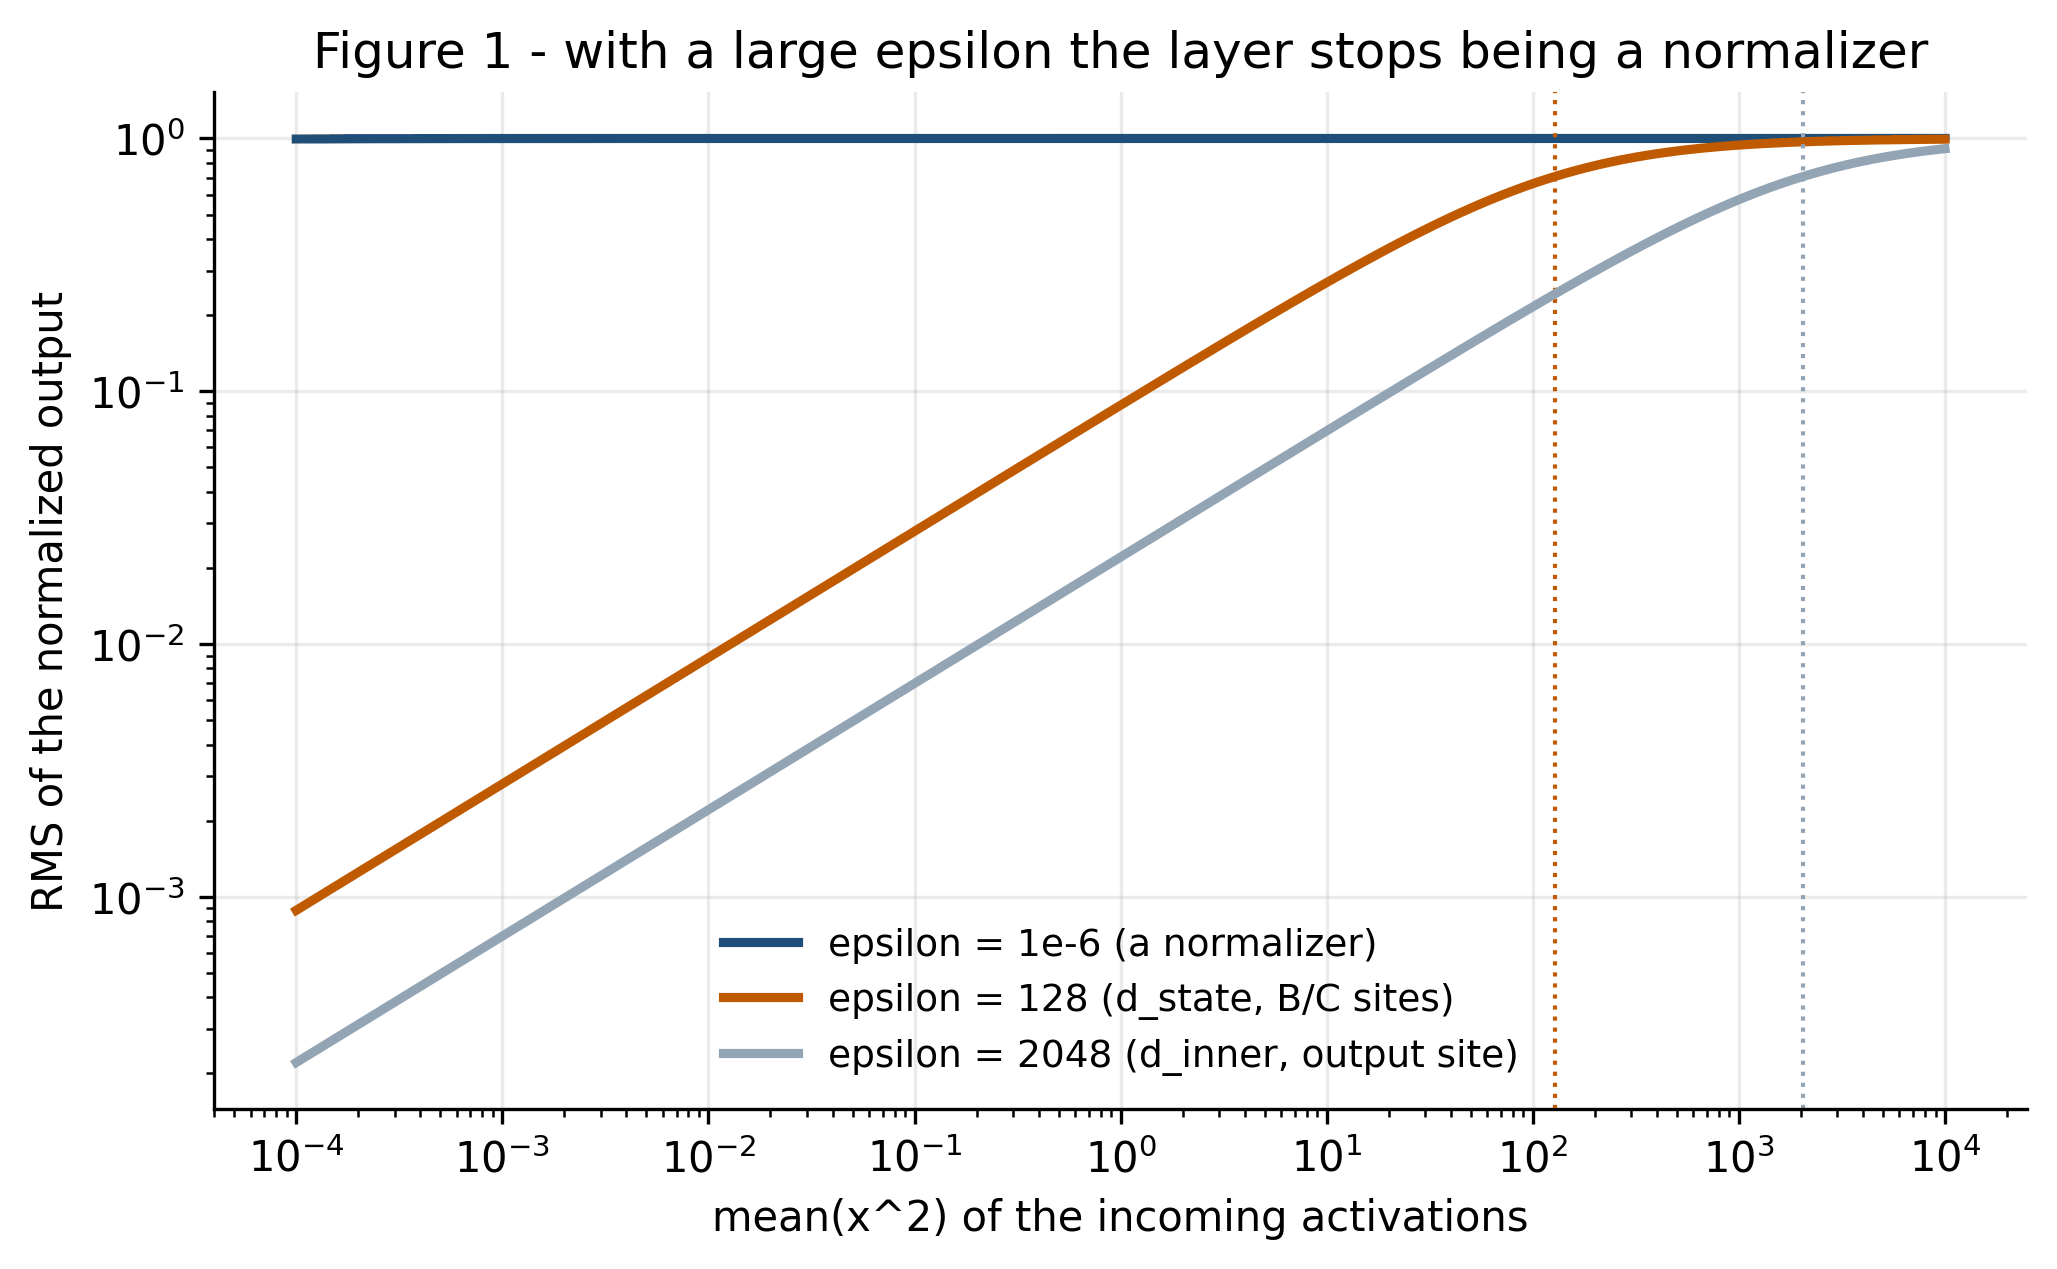

In [2]:
ms = np.logspace(-4, 4, 400)          # mean of squares of the incoming activations
def out_rms(ms, eps):
    """RMS of x / sqrt(mean(x^2) + eps), for an input with that mean-of-squares."""
    return np.sqrt(ms) / np.sqrt(ms + eps)

fig, ax = plt.subplots(figsize=(7.8, 4.4))
for eps, c, lab in [(EPS_FIXED, INK, "epsilon = 1e-6 (a normalizer)"),
                    (128, WARN, "epsilon = 128 (d_state, B/C sites)"),
                    (2048, GREY, "epsilon = 2048 (d_inner, output site)")]:
    ax.plot(ms, out_rms(ms, eps), lw=2.2, color=c, label=lab)
    if eps > 1:
        ax.axvline(eps, ls=":", lw=1, color=c)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("mean(x^2) of the incoming activations")
ax.set_ylabel("RMS of the normalized output")
ax.set_title("Figure 1 - with a large epsilon the layer stops being a normalizer")
ax.legend(frameon=False, fontsize=9); show(fig)

*A normalizer holds its output at unit RMS whatever comes in; with epsilon set to the feature count it passes the input through, scaled by a constant, for every activation scale below that count.*

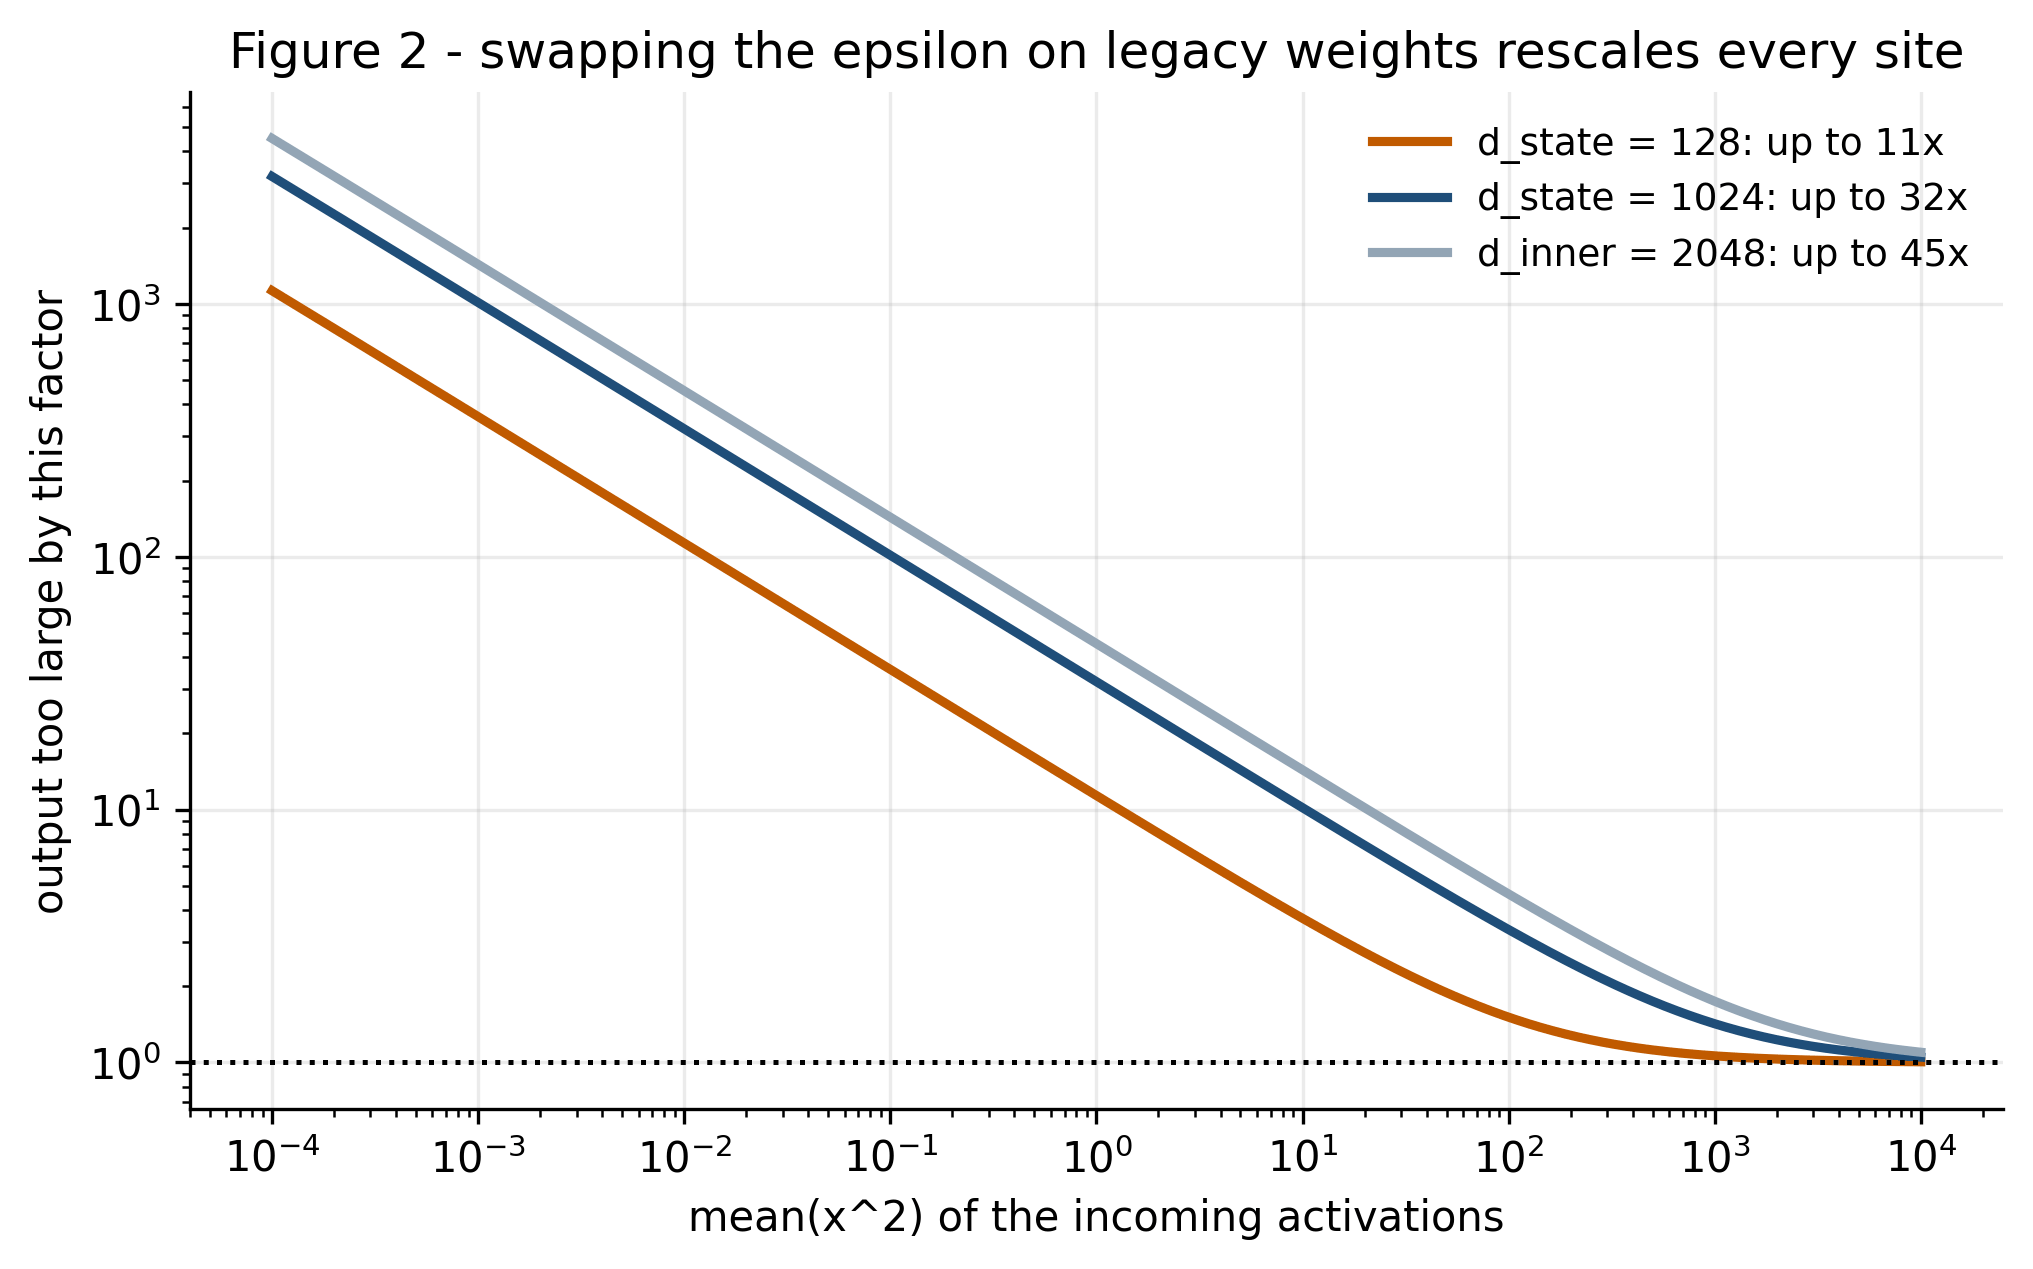

In [3]:
fig, ax = plt.subplots(figsize=(7.8, 4.4))
for eps, c, lab in [(128, WARN, "d_state = 128"), (1024, INK, "d_state = 1024"),
                    (2048, GREY, "d_inner = 2048")]:
    gain = np.sqrt(ms + eps) / np.sqrt(ms + EPS_FIXED)
    ax.plot(ms, gain, lw=2.2, color=c, label=f"{lab}: up to {np.sqrt(eps):.0f}x")
ax.axhline(1, ls=":", color="k", lw=1.2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("mean(x^2) of the incoming activations")
ax.set_ylabel("output too large by this factor")
ax.set_title("Figure 2 - swapping the epsilon on legacy weights rescales every site")
ax.legend(frameon=False, fontsize=9); show(fig)

*Evaluating legacy weights at epsilon=1e-6 therefore leaves every normalized tensor too large by up to sqrt(d), which is 11x at d_state=128 and 45x at d_inner=2048.*

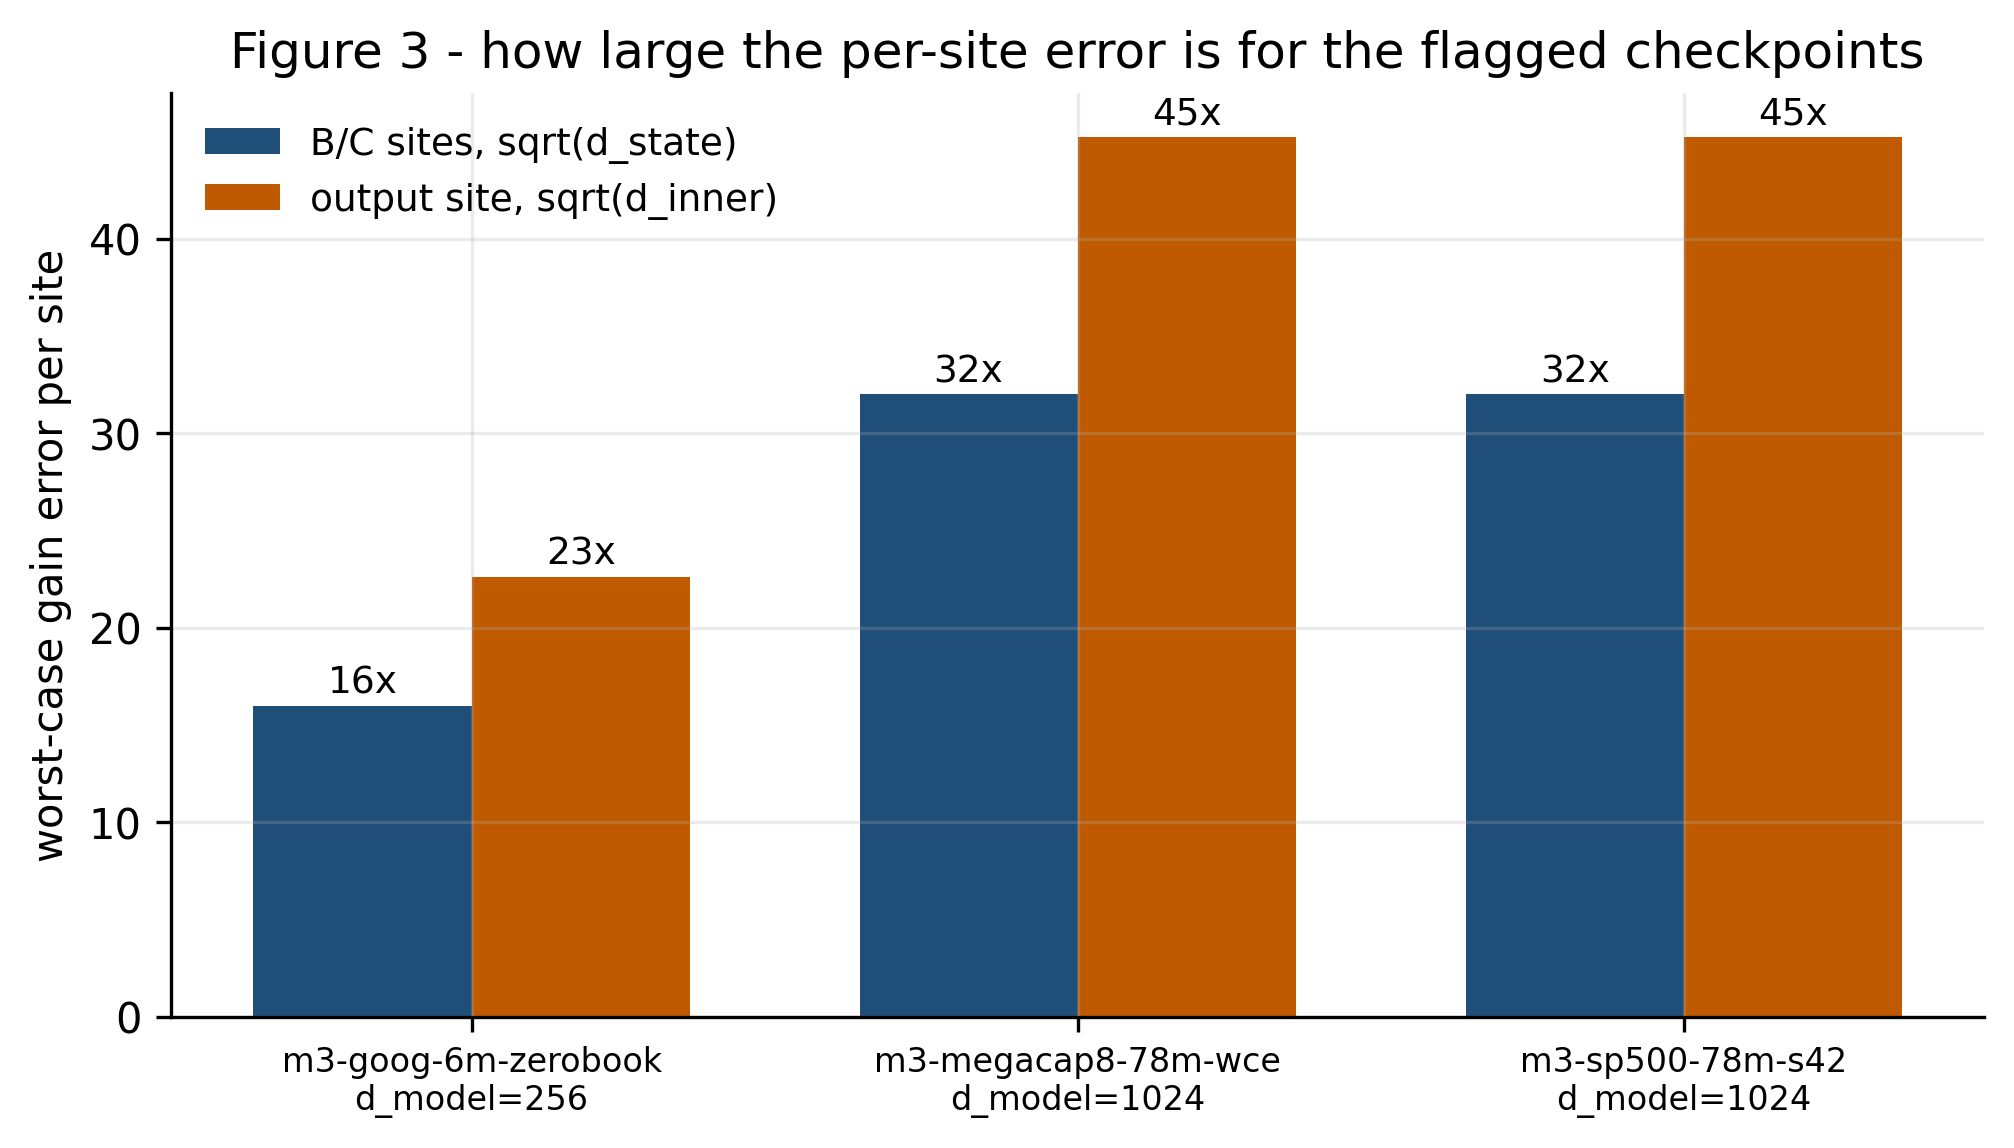

In [4]:
# Per-checkpoint geometry: B/C see d_state, the output norm sees d_inner.
rows = []
for m in FLAGGED:
    d = REG[m]["d_model"]
    rows.append((m, d, 2 * d))       # d_inner = expand factor 2 in this family
fig, ax = plt.subplots(figsize=(7.8, 4.0))
w = .36
xs = np.arange(len(rows))
bc = [np.sqrt(r[1]) for r in rows]
oc = [np.sqrt(r[2]) for r in rows]
ax.bar(xs - w/2, bc, w, color=INK, label="B/C sites, sqrt(d_state)")
ax.bar(xs + w/2, oc, w, color=WARN, label="output site, sqrt(d_inner)")
for i, (b, o) in enumerate(zip(bc, oc)):
    ax.annotate(f"{b:.0f}x", (i - w/2, b), ha="center", fontsize=9,
                xytext=(0, 3), textcoords="offset points")
    ax.annotate(f"{o:.0f}x", (i + w/2, o), ha="center", fontsize=9,
                xytext=(0, 3), textcoords="offset points")
ax.set_xticks(xs); ax.set_xticklabels([f"{r[0]}\nd_model={r[1]}" for r in rows], fontsize=8)
ax.set_ylabel("worst-case gain error per site")
ax.set_title("Figure 3 - how large the per-site error is for the flagged checkpoints")
ax.legend(frameon=False, fontsize=9); show(fig)

*Each of the two flagged checkpoints has three such sites per layer, and the size of the error is fixed by its own geometry.*

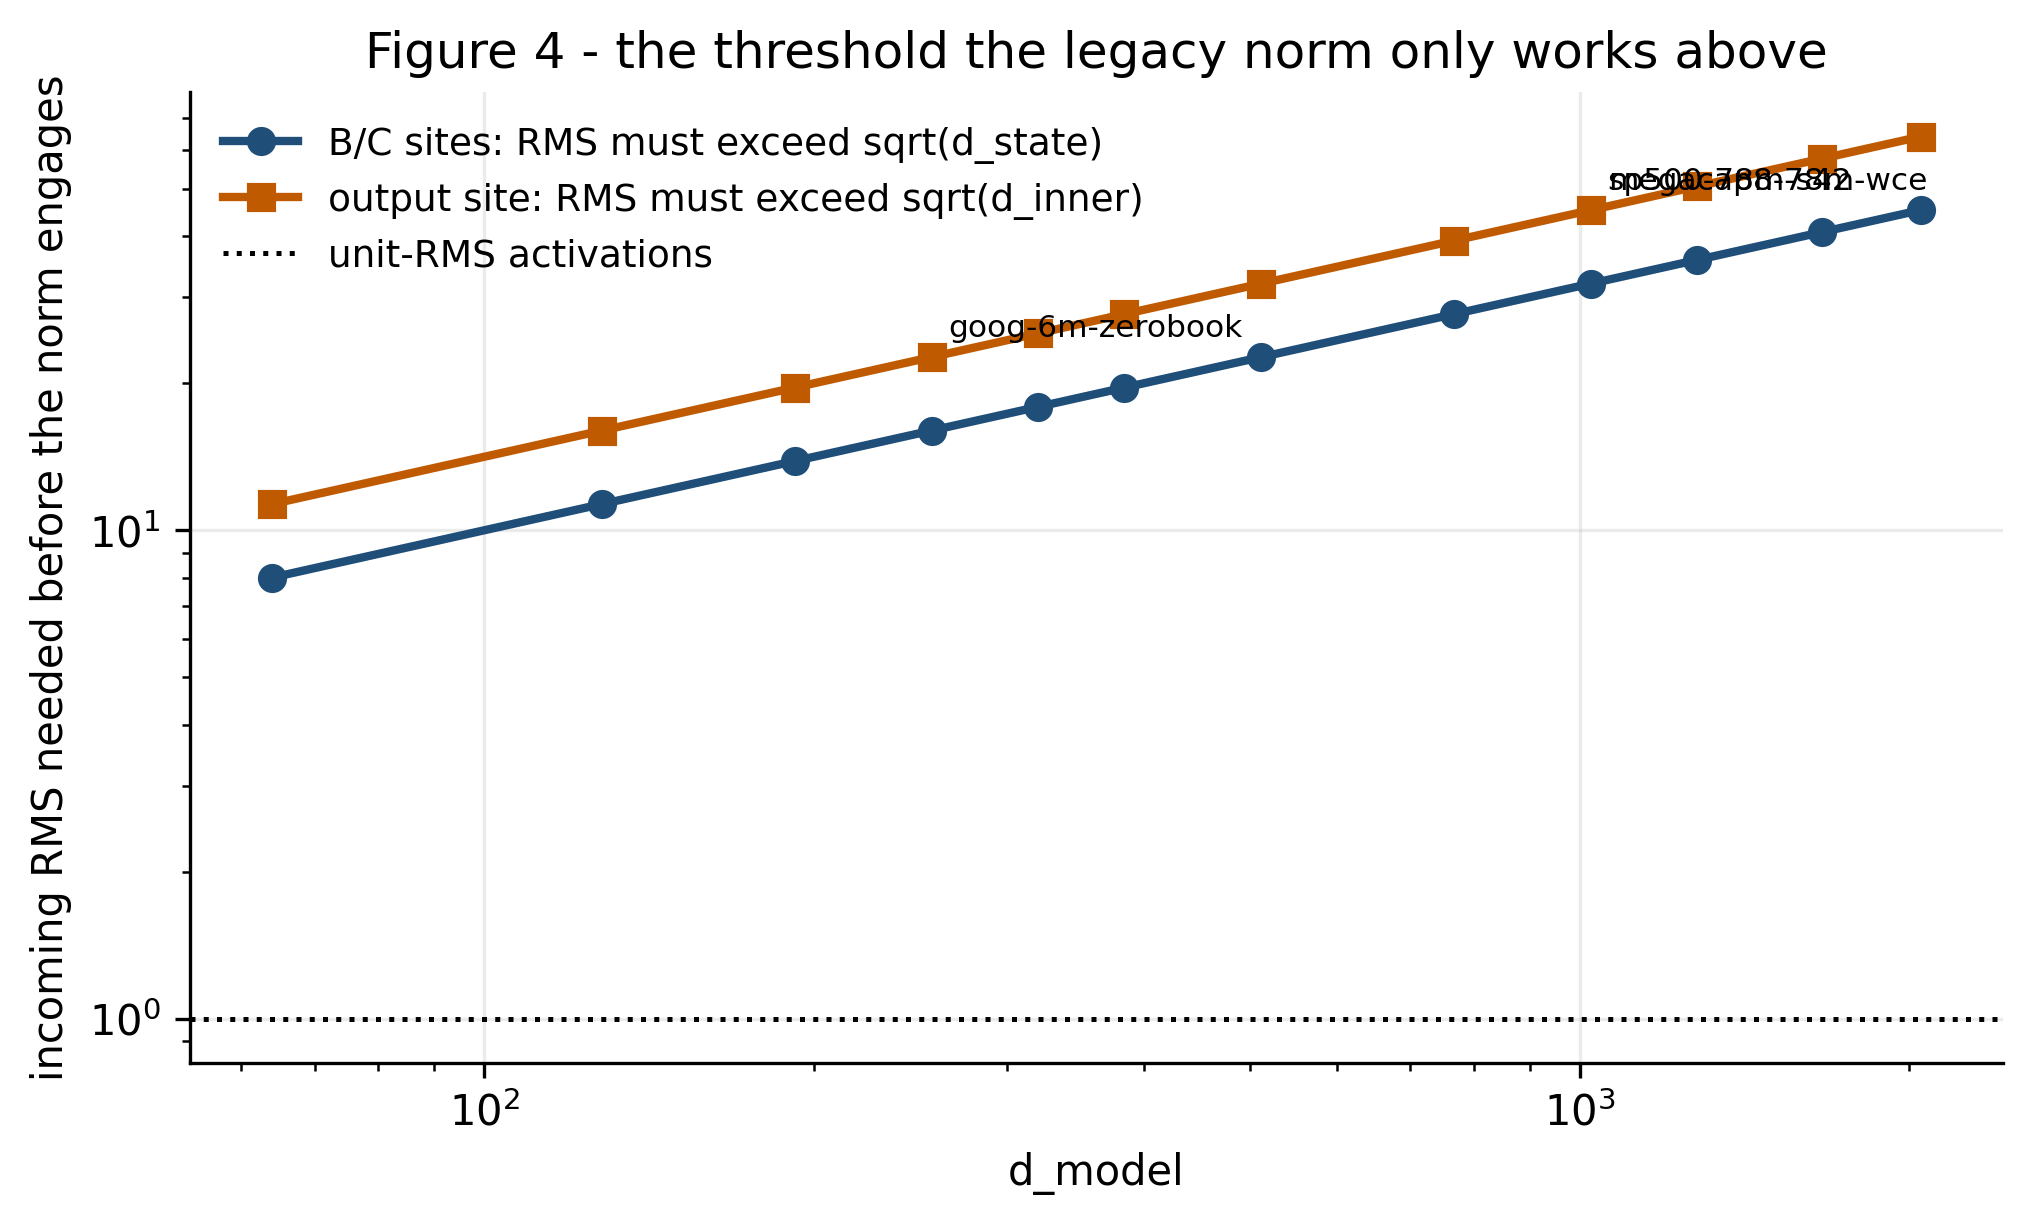

In [5]:
# Where the legacy normalizer starts behaving like a normalizer at all: the
# incoming RMS has to reach sqrt(eps), and eps is the feature count.
ds = sorted({REG[m]["d_model"] for m in REG if REG[m].get("d_model")})
fig, ax = plt.subplots(figsize=(7.8, 4.2))
ax.plot(ds, [np.sqrt(d) for d in ds], marker="o", lw=2, color=INK,
        label="B/C sites: RMS must exceed sqrt(d_state)")
ax.plot(ds, [np.sqrt(2 * d) for d in ds], marker="s", lw=2, color=WARN,
        label="output site: RMS must exceed sqrt(d_inner)")
ax.axhline(1.0, ls=":", color="k", lw=1.2, label="unit-RMS activations")
for m in FLAGGED:
    d = REG[m]["d_model"]
    ax.annotate(m.replace("m3-", ""), (d, np.sqrt(2 * d)), fontsize=7.5,
                xytext=(4, 5), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("d_model"); ax.set_ylabel("incoming RMS needed before the norm engages")
ax.set_title("Figure 4 - the threshold the legacy norm only works above")
ax.legend(frameon=False, fontsize=9); show(fig)

*The legacy normalizer only starts normalizing once the incoming RMS reaches sqrt of the feature count -- 16 to 64 for these models, against the unit scale activations usually sit at. How far below that threshold these particular checkpoints actually run is not measured here.*

## What it cost, measured

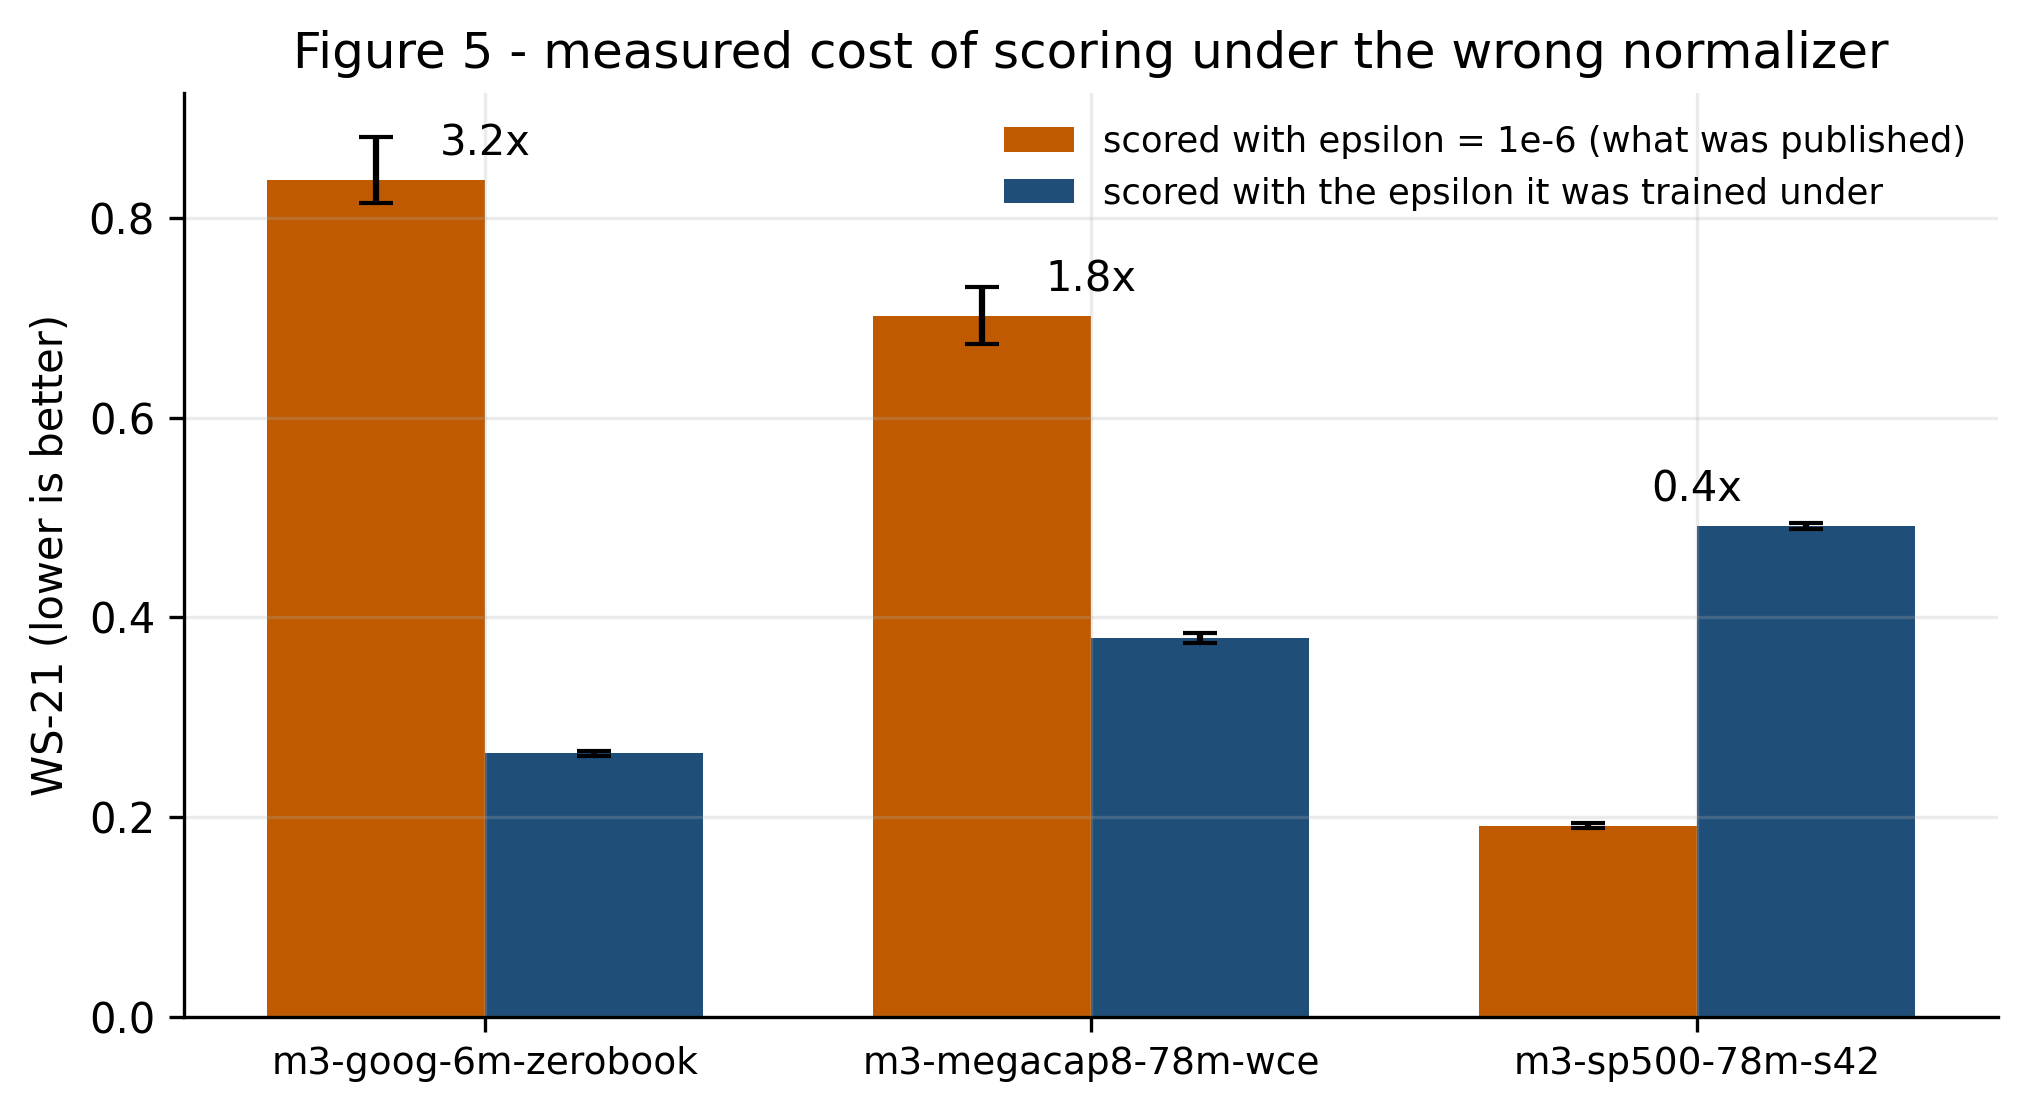

In [6]:
fig, ax = plt.subplots(figsize=(7.8, 4.0))
xs = np.arange(len(FLAGGED)); w = .36
a_all = [ws(FIXED, m) for m in FLAGGED]
b_all = [ws(LEGACY, m) for m in FLAGGED]
am = [st.mean(v) for v in a_all]; bm = [st.mean(v) for v in b_all]
ax.bar(xs - w/2, am, w, color=WARN, yerr=[[m - min(v) for m, v in zip(am, a_all)],
                                          [max(v) - m for m, v in zip(am, a_all)]],
       capsize=4, label="scored with epsilon = 1e-6 (what was published)")
ax.bar(xs + w/2, bm, w, color=INK, yerr=[[m - min(v) for m, v in zip(bm, b_all)],
                                         [max(v) - m for m, v in zip(bm, b_all)]],
       capsize=4, label="scored with the epsilon it was trained under")
for i, (a, b) in enumerate(zip(am, bm)):
    ax.annotate(f"{a/b:.1f}x", ((i - w/2 + i + w/2) / 2 + i * 0, max(a, b)),
                ha="center", fontsize=10, xytext=(0, 6), textcoords="offset points")
ax.set_xticks(xs); ax.set_xticklabels(FLAGGED, fontsize=9)
ax.set_ylabel("WS-21 (lower is better)")
ax.set_title("Figure 5 - measured cost of scoring under the wrong normalizer")
ax.legend(frameon=False, fontsize=8.5); show(fig)

*Restoring the training-time epsilon moves both checkpoints by more than the entire spread of the leaderboard they sit in.*

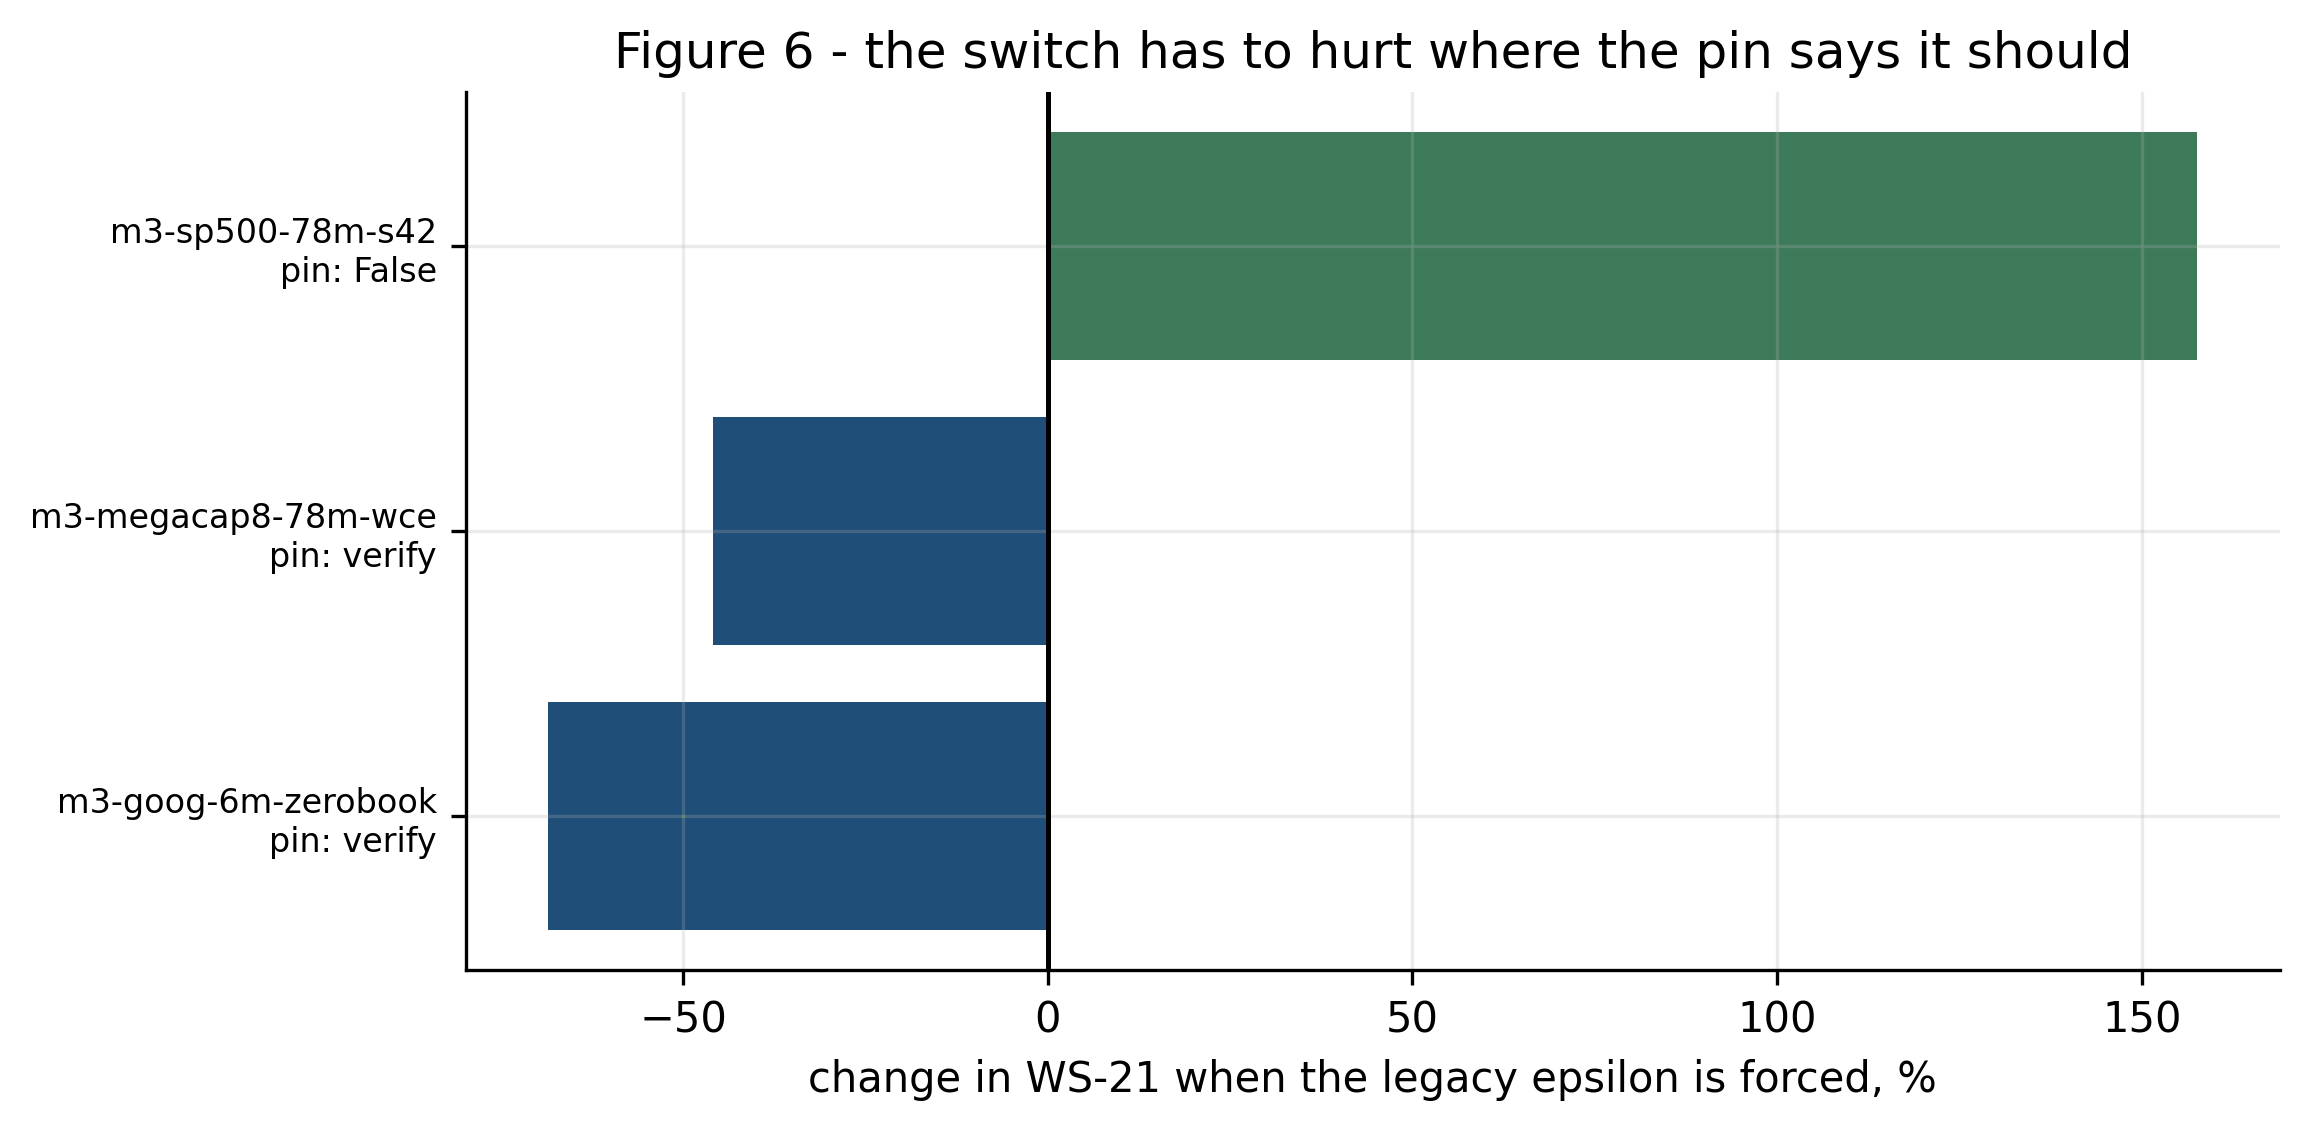

In [7]:
ctl = [m for m in LEGACY if PINS.get(m) is False]
fig, ax = plt.subplots(figsize=(7.8, 3.8))
names, delta, cols = [], [], []
for m in sorted(LEGACY):
    a, b = st.mean(ws(FIXED, m)), st.mean(ws(LEGACY, m))
    names.append(f"{m}\npin: {PINS.get(m)}")
    delta.append((b - a) / a * 100)
    cols.append(INK if PINS.get(m) == "verify" else GOOD)
ax.barh(np.arange(len(names)), delta, color=cols)
ax.axvline(0, color="k", lw=1.2)
ax.set_yticks(np.arange(len(names))); ax.set_yticklabels(names, fontsize=8)
ax.set_xlabel("change in WS-21 when the legacy epsilon is forced, %")
ax.set_title("Figure 6 - the switch has to hurt where the pin says it should")
show(fig)

*Forced onto a checkpoint whose pin says it was trained with the small epsilon, the same switch makes the score worse: this is a correction, not a setting that flatters everything.*

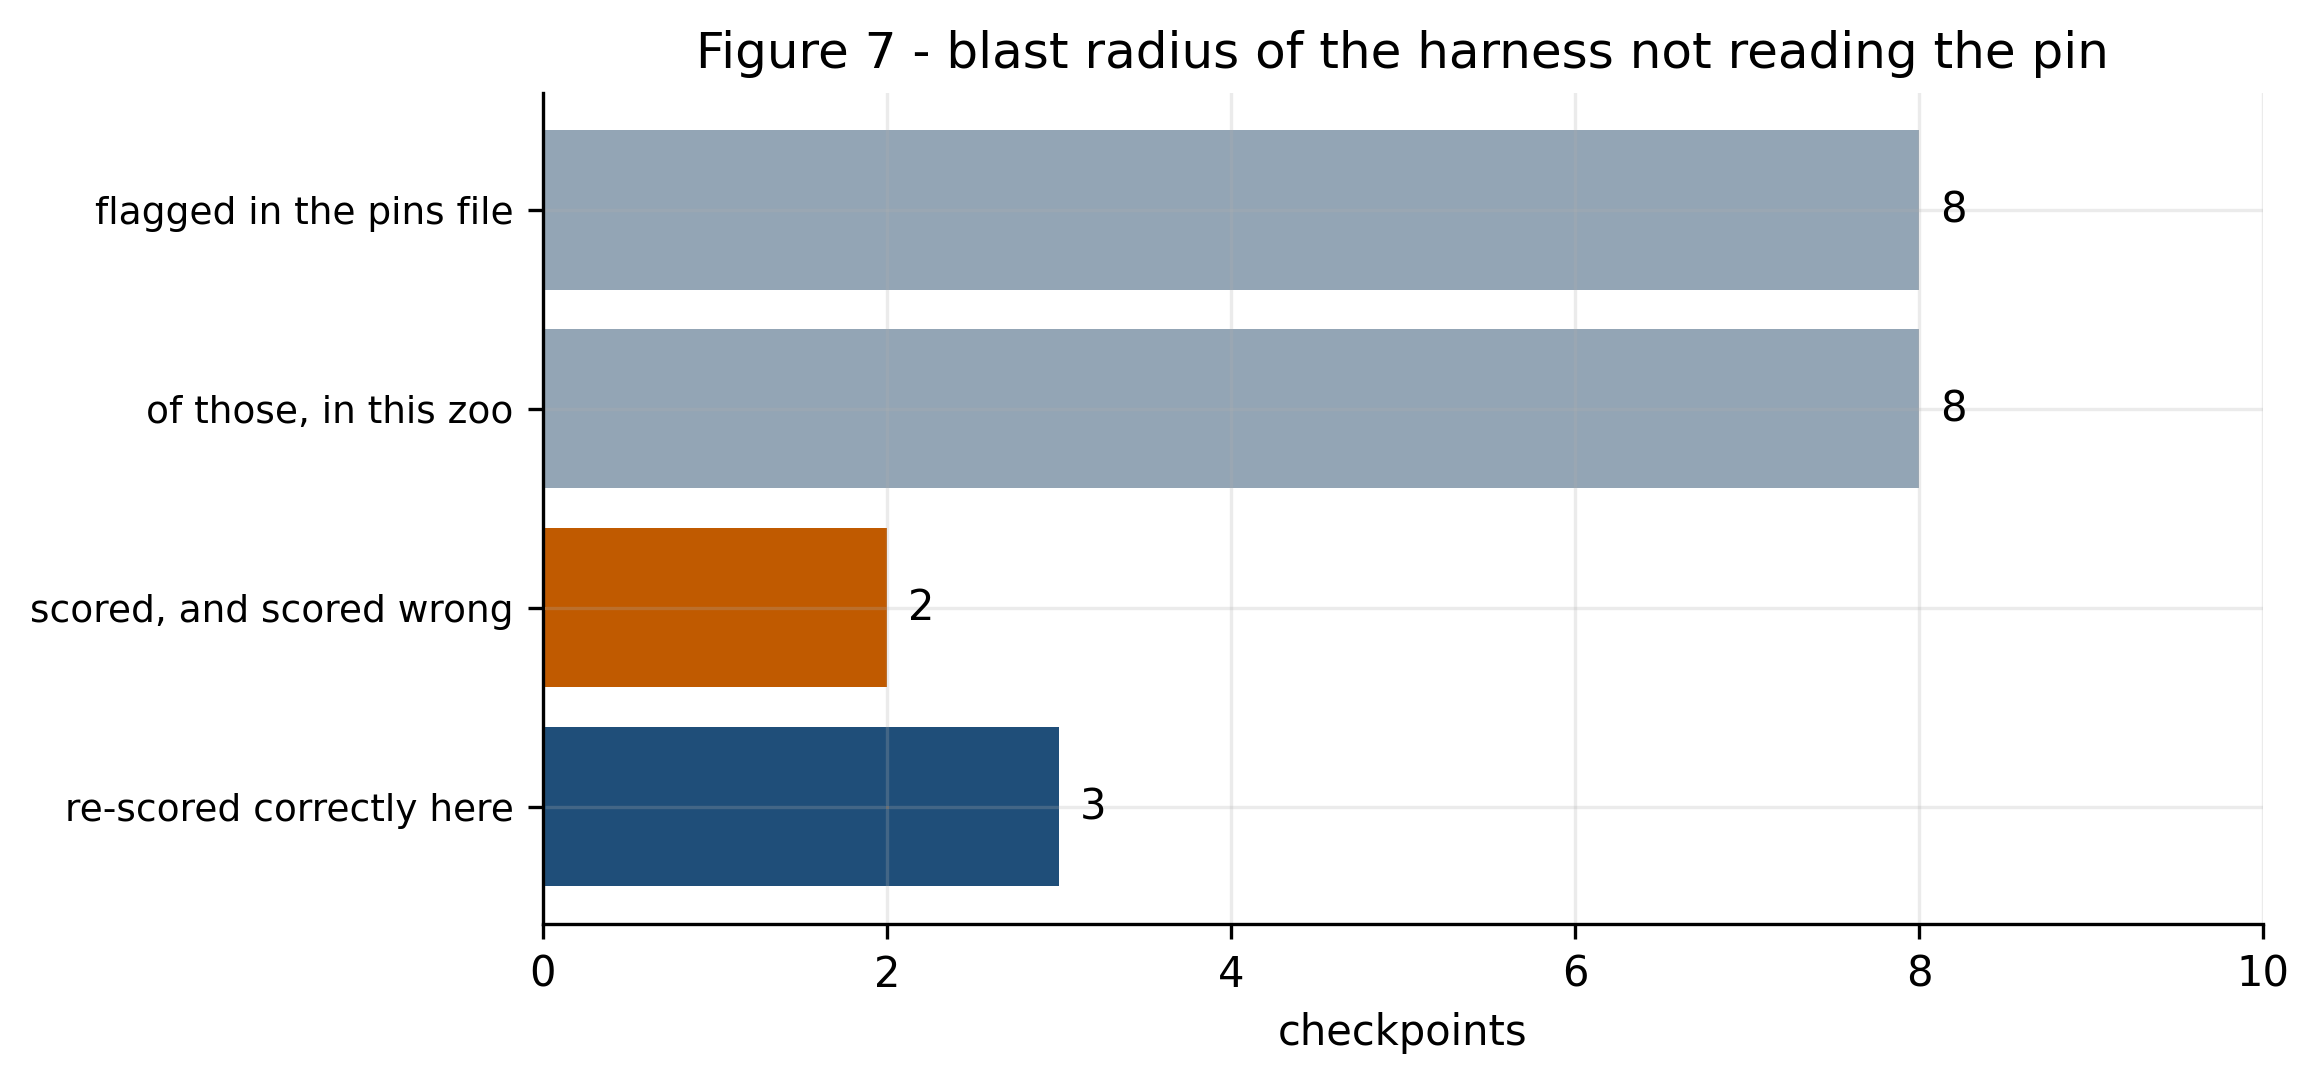

In [8]:
flagged = [m for m, v in PINS.items() if v == "verify"]
in_zoo = [m for m in flagged if m in REG]
scored_wrong = [m for m in in_zoo if m in FIXED]
unrunnable = [m for m in in_zoo if m not in FIXED]
fig, ax = plt.subplots(figsize=(7.4, 3.6))
groups = [("flagged in the pins file", len(flagged), GREY),
          ("of those, in this zoo", len(in_zoo), GREY),
          ("scored, and scored wrong", len(scored_wrong), WARN),
          ("re-scored correctly here", len(LEGACY), INK)]
ax.barh(np.arange(len(groups)), [g[1] for g in groups], color=[g[2] for g in groups])
for i, g in enumerate(groups):
    ax.annotate(str(g[1]), (g[1], i), va="center", fontsize=10,
                xytext=(5, 0), textcoords="offset points")
ax.set_yticks(np.arange(len(groups))); ax.set_yticklabels([g[0] for g in groups], fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("checkpoints")
ax.set_xlim(0, len(flagged) * 1.25)
ax.set_title("Figure 7 - blast radius of the harness not reading the pin")
show(fig)

*The pins file flags more checkpoints than this zoo scored; the ones that got a wrong number are the intersection.*

### Table 1 - the two corrected rows

In [9]:
rows = []
for m in sorted(LEGACY):
    a, b = ws(FIXED, m), ws(LEGACY, m)
    rows.append({"checkpoint": m, "pin": str(PINS.get(m)),
                 "published (eps=1e-6)": round(st.mean(a), 4), "seeds": len(a),
                 "corrected (eps=trained)": round(st.mean(b), 4), "seeds ": len(b),
                 "ratio": round(st.mean(a) / st.mean(b), 2)})
pd.DataFrame(rows).set_index("checkpoint")

,pin,published (eps=1e-6),seeds,corrected (eps=trained),seeds,ratio
checkpoint,,,,,,
m3-goog-6m-zerobook,verify,0.8379,3,0.2643,3,3.17
m3-megacap8-78m-wce,verify,0.7012,3,0.3792,3,1.85
m3-sp500-78m-s42,False,0.1908,3,0.4914,2,0.39


### Table 2 - the epsilon at each site

In [10]:
sites = []
for m in FLAGGED:
    d = REG[m]["d_model"]
    for site, eps in [("B_norm", d), ("C_norm", d), ("out_norm", 2 * d)]:
        sites.append({"checkpoint": m, "site": site,
                      "epsilon it was trained with": eps,
                      "epsilon the harness used": EPS_FIXED,
                      "gain error at mean(x^2)=1": round(np.sqrt((1 + eps) / (1 + EPS_FIXED)), 1)})
pd.DataFrame(sites).set_index(["checkpoint", "site"])

epsilon it was trained with  \
checkpoint          site                                    
m3-goog-6m-zerobook B_norm                            256   
                    C_norm                            256   
                    out_norm                          512   
m3-megacap8-78m-wce B_norm                           1024   
                    C_norm                           1024   
                    out_norm                         2048   
m3-sp500-78m-s42    B_norm                           1024   
                    C_norm                           1024   
                    out_norm                         2048   

                              epsilon the harness used  \
checkpoint          site                                 
m3-goog-6m-zerobook B_norm                    0.000001   
                    C_norm                    0.000001   
                    out_norm                  0.000001   
m3-megacap8-78m-wce B_norm                    0.000001   
                    C_norm                    0.000001   
                    out_norm                  0.000001   
m3-sp500-78m-s42    B_norm                    0.000001   
                    C_norm                    0.000001   
                    out_norm                  0.000001   

                              gain error at mean(x^2)=1  
checkpoint          site                                 
m3-goog-6m-zerobook B_norm                         16.0  
                    C_norm                         16.0  
                    out_norm                       22.6  
m3-megacap8-78m-wce B_norm                         32.0  
                    C_norm                         32.0  
                    out_norm                       45.3  
m3-sp500-78m-s42    B_norm                         32.0  
                    C_norm                         32.0  
                    out_norm                       45.3

## Conclusions

1. **The defect is a naming collision between two frameworks, not a modelling
   choice.** `nn.RMSNorm(d)` means `normalized_shape=d` in PyTorch and
   `epsilon=d` in Flax. Nothing warns, and the network still trains -- it just
   trains without a working normalizer at three sites per layer.
2. **Scoring legacy weights at the corrected epsilon is not a small error.**
   Every normalized tensor comes out up to sqrt(d) too large -- 11x at
   d_state=128, 45x at d_inner=2048 -- at three sites in every layer. What that
   does after the residual stream and the later norms is not traced here; the
   end-to-end cost is measured instead, at 3.2x and 1.9x in WS-21.
3. **The record needed to prevent it already existed.** The pin is in
   `model_store_pins.json` and the runtime already honours
   `MAMBA3_LEGACY_NORM`; only the benchmark harness ignored it. The fix is to
   read the pin, and the test is that forcing the switch the other way makes a
   fixed-epsilon checkpoint worse.
4. **This explains two outliers, not the gap to the old reference.** The
   pre-fix 78M Mamba3 scored WS-21 0.0438; the best current checkpoint is
   0.1769, still 4x away, and both flagged checkpoints stay well above it even
   after correction. Whether the legacy semantics have to be present *from the
   start of training* is what `artifacts/rmsnorm_train_ab/` was written to
   settle, and that train-time A/B has never run.